# Intro

Loading the necesary packages and setting some parameters to be used throughout for consistency.

In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from scipy import stats

from sklearn.ensemble import RandomForestRegressor

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 150)
RANDOM_STATE = 42

Defining the data path, target variable, the id column, which variables are causing data leakage (to be removed), and which variables are not controlable by the student.

In [31]:
#DATA_PATH = "Data/student_exam_performance.csv"
TARGET = "exam_score"
DATA_PATH = "student_exam_performance.csv"

ID_COLS = ["student_id"]
LEAKAGE_COLS = [
    "questions_attempted",
    "questions_correct",
    "performance_grade",
    "pass_status",
    "performance_level",
]

REDUNDANT_COLS= [
    "study_hours_per_day",
    "online_learning_hours",
    "exam_anxiety_level",
    "previous_gpa",
    "internet_access",
]

NOT_CONTROLLABLE = [
    "age", "gender", "education_level", "school_type", "family_income",
    "parent_education", "urban_rural", "previous_exam_score", "previous_gpa",
    "exam_difficulty", "internet_access", "device_availability",
]

# Load Data

Reading in the data and seeing what it actually is about (no duplicates but many missing values).

In [33]:
df = pd.read_csv(DATA_PATH)

print(f"Shape: {df.shape[0]:,} rows x {df.shape[1]} columns")
print(f"Duplicate rows: {df.duplicated().sum()}")
for c in ID_COLS:
    print(f"'{c}' unique: {df[c].is_unique}")
df.head()

Shape: 100,000 rows x 44 columns
Duplicate rows: 0
'student_id' unique: True


,student_id,age,gender,education_level,school_type,family_income,parent_education,urban_rural,previous_exam_score,previous_gpa,attendance_percentage,assignment_completion_rate,class_participation,study_hours_per_day,self_study_hours,private_tuition,online_learning_hours,study_consistency,study_environment,study_method,revision_frequency,practice_tests_completed,notes_quality,sleep_hours,sleep_quality,daily_screen_time,physical_activity_hours,break_frequency,stress_level,motivation_level,internet_access,device_availability,educational_app_usage,online_course_hours,exam_difficulty,exam_preparation_days,questions_attempted,questions_correct,time_management_score,exam_anxiety_level,exam_score,performance_grade,pass_status,performance_level
0,STU_000001,20,Female,High School,Public,Middle,NaN,Rural,78.36,2.95,81.49,65.18,Medium,4.94,2.63,0,1.75,Medium,Moderate,Flashcards,Rarely,8,Average,6.31,Excellent,3.80,0.93,Frequently,10,High,1,Shared,Low,2.15,Medium,27,95,86,NaN,9.39,90.40,A,Pass,High
1,STU_000002,17,Male,High School,Public,Middle,NaN,Suburban,73.40,2.89,NaN,76.53,Low,3.42,2.64,0,1.97,Medium,Moderate,Flashcards,Daily,10,Average,6.81,Excellent,4.04,0.21,Frequently,8,High,1,Shared,Moderate,4.37,Easy,4,100,86,87.17,6.31,86.21,A,Pass,High
2,STU_000003,18,Other,Undergraduate,Public,Middle,Master,Urban,82.76,3.35,100.00,70.39,Medium,1.06,0.83,0,3.40,Low,Moderate,Summarizing,Weekly,5,Excellent,6.53,Poor,3.19,2.56,Rarely,9,Medium,1,Dedicated,Low,1.43,Easy,28,96,74,63.77,9.87,76.11,B,Pass,Medium
3,STU_000004,20,Male,High School,Public,Middle,High School,Suburban,60.61,2.57,84.91,75.06,Low,7.89,5.51,0,1.94,Medium,Quiet,Summarizing,Weekly,8,Excellent,6.60,Fair,5.12,2.30,Rarely,10,High,1,Dedicated,Low,3.69,Medium,16,97,77,59.51,9.68,79.74,B,Pass,Medium
4,STU_000005,16,Female,High School,Private,High,Bachelor,Suburban,74.79,2.84,88.21,61.54,Medium,2.63,2.29,0,0.58,Medium,Noisy,Self-Reading,Rarely,1,Poor,7.83,Excellent,4.82,0.49,Frequently,10,High,1,Dedicated,Moderate,1.97,Medium,28,98,52,84.64,10.00,50.66,D,Pass,Low


Separating the features from id, leakage variables and the target. Further dividing it by type, so binary, numeric (except the binary ones) and cathegorical. 

In [34]:
features = [c for c in df.columns if c not in ID_COLS + LEAKAGE_COLS + REDUNDANT_COLS + [TARGET]]

is_num = lambda c: pd.api.types.is_numeric_dtype(df[c])
binary_cols = [c for c in features if is_num(c) and df[c].dropna().nunique() == 2]
num_cols = [c for c in features if is_num(c) and c not in binary_cols]
cat_cols = [c for c in features if not is_num(c)]

print(f"{len(features)} candidate features")
print("Continuous/count numeric:", num_cols)
print("Binary (0/1):", binary_cols)
print("Categorical:", cat_cols)

32 candidate features
Continuous/count numeric: ['age', 'previous_exam_score', 'attendance_percentage', 'assignment_completion_rate', 'self_study_hours', 'practice_tests_completed', 'sleep_hours', 'daily_screen_time', 'physical_activity_hours', 'stress_level', 'online_course_hours', 'exam_preparation_days', 'time_management_score']
Binary (0/1): ['private_tuition']
Categorical: ['gender', 'education_level', 'school_type', 'family_income', 'parent_education', 'urban_rural', 'class_participation', 'study_consistency', 'study_environment', 'study_method', 'revision_frequency', 'notes_quality', 'sleep_quality', 'break_frequency', 'motivation_level', 'device_availability', 'educational_app_usage', 'exam_difficulty']


Taking a look at the numerical variables and their spread.

In [35]:
df[num_cols + binary_cols + [TARGET]].describe().T

,count,mean,std,min,25%,50%,75%,max
age,100000.0,17.005740,1.999562,14.00,15.00,17.00,19.0000,20.00
previous_exam_score,100000.0,69.531033,11.379108,30.00,61.82,69.53,77.2325,100.00
attendance_percentage,90137.0,84.616882,7.922485,46.34,79.21,84.75,90.1700,100.00
assignment_completion_rate,100000.0,69.724405,12.127179,20.00,61.48,69.57,77.9200,100.00
self_study_hours,100000.0,2.094970,1.266066,0.25,1.17,1.84,2.7300,10.00
practice_tests_completed,100000.0,5.509170,2.501131,0.00,4.00,5.00,7.0000,20.00
sleep_hours,100000.0,6.995102,1.200874,3.00,6.18,7.00,7.8100,11.00
daily_screen_time,100000.0,5.000495,1.775716,1.00,3.77,4.99,6.2100,12.08
physical_activity_hours,100000.0,2.487579,2.413386,0.00,0.72,1.73,3.4800,12.00
stress_level,100000.0,9.375640,1.081613,5.00,9.00,10.00,10.0000,10.00


# Data Quality

Which values are missing and what to do with them?

In [10]:
miss = (df[features].isna().mean() * 100).round(2)
miss = miss[miss > 0].sort_values(ascending=False).rename("% missing")
display(miss.to_frame())

rows_lost = len(df) - len(df.dropna(subset=features))
print(f"dropna() would remove {rows_lost:,} of {len(df):,} rows ({rows_lost / len(df):.0%})")

,% missing
attendance_percentage,9.86
time_management_score,9.61
notes_quality,8.41
previous_gpa,7.79
sleep_quality,6.99
parent_education,6.53
device_availability,2.96


dropna() would remove 41,940 of 100,000 rows (42%)


We could just remove them, but then that would be half the data set.

In [11]:
rows = []
for c in miss.index:
    s_miss = df.loc[df[c].isna(), TARGET]
    s_ok = df.loc[df[c].notna(), TARGET]
    rows.append({
        "column": c,
        "mean score (missing)": s_miss.mean(),
        "mean score (present)": s_ok.mean(),
        "difference": s_miss.mean() - s_ok.mean(),
        "p-value": stats.mannwhitneyu(s_miss, s_ok).pvalue,
    })
pd.DataFrame(rows).set_index("column").round(3)

,mean score (missing),mean score (present),difference,p-value
column,,,,
attendance_percentage,61.967,61.948,0.019,0.840
time_management_score,62.141,61.930,0.211,0.109
notes_quality,62.231,61.924,0.306,0.122
previous_gpa,62.042,61.942,0.100,0.633
sleep_quality,62.080,61.940,0.139,0.610
parent_education,62.181,61.934,0.247,0.420
device_availability,61.875,61.952,-0.078,0.688


# Distribution plots

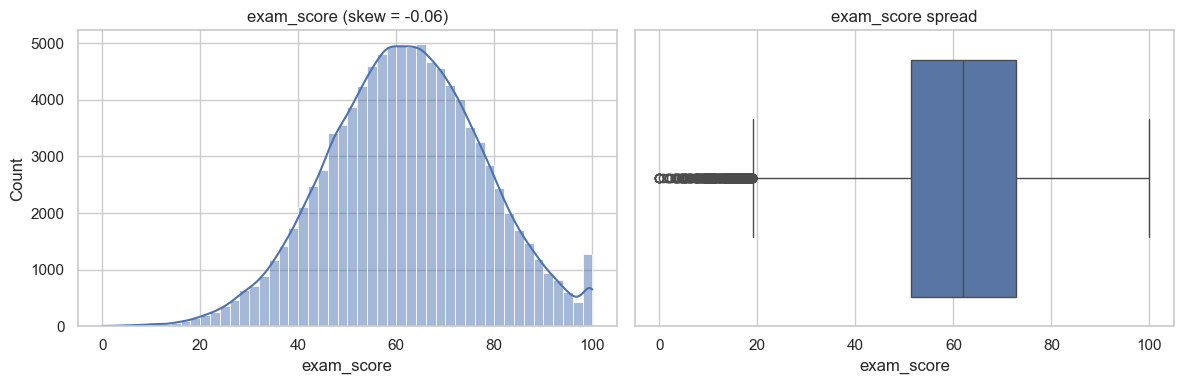

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(df[TARGET], bins=50, kde=True, ax=axes[0])
axes[0].set_title(f"exam_score (skew = {df[TARGET].skew():.2f})")
sns.boxplot(x=df[TARGET], ax=axes[1])
axes[1].set_title("exam_score spread")
plt.tight_layout()
plt.show()

Numerical values

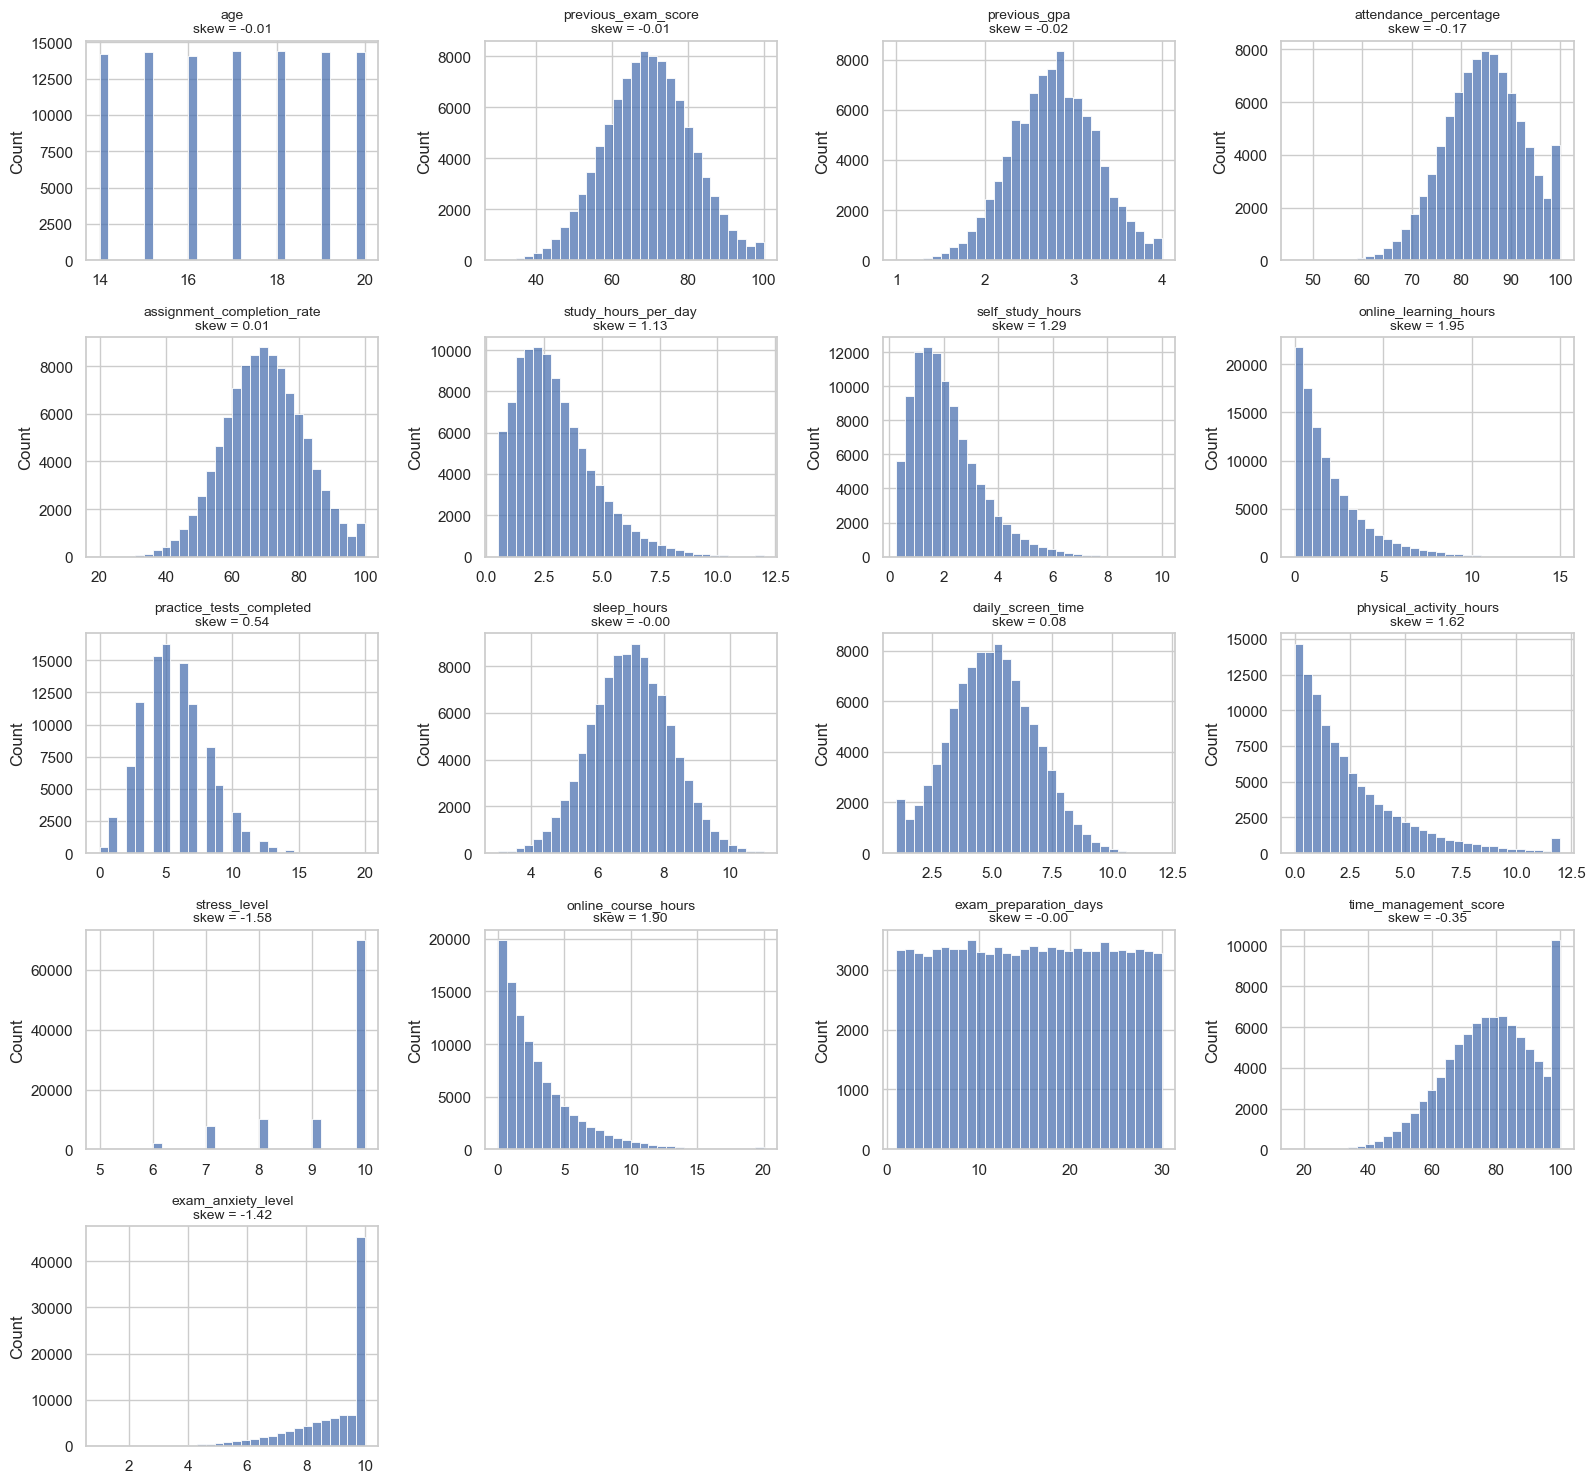

In [13]:
def hist_grid(cols, ncols=4):
    nrows = int(np.ceil(len(cols) / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(4 * ncols, 3 * nrows))
    axes = np.atleast_1d(axes).ravel()
    for ax, c in zip(axes, cols):
        sns.histplot(df[c].dropna(), bins=30, ax=ax)
        ax.set_title(f"{c}\nskew = {df[c].skew():.2f}", fontsize=10)
        ax.set_xlabel("")
    for ax in axes[len(cols):]:
        ax.axis("off")
    plt.tight_layout()
    plt.show()

hist_grid(num_cols)

In [14]:
skew = df[num_cols].skew().sort_values()
print("Most skewed numeric columns:")
display(skew[skew.abs() > 1].to_frame("skew"))

Most skewed numeric columns:


,skew
stress_level,-1.582138
exam_anxiety_level,-1.421268
study_hours_per_day,1.131956
self_study_hours,1.287089
physical_activity_hours,1.619581
online_course_hours,1.901414
online_learning_hours,1.945409


Binary and cathegorical values

/var/folders/nc/59r_nr9j10df9yjwcyrl2x0m0000gn/T/ipykernel_23961/3917981318.py:6: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  vc = df[c].astype("object").fillna("Missing").value_counts(normalize=True)
/var/folders/nc/59r_nr9j10df9yjwcyrl2x0m0000gn/T/ipykernel_23961/3917981318.py:6: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  vc = df[c].astype("object").fillna("Missing").value_counts(normalize=True)


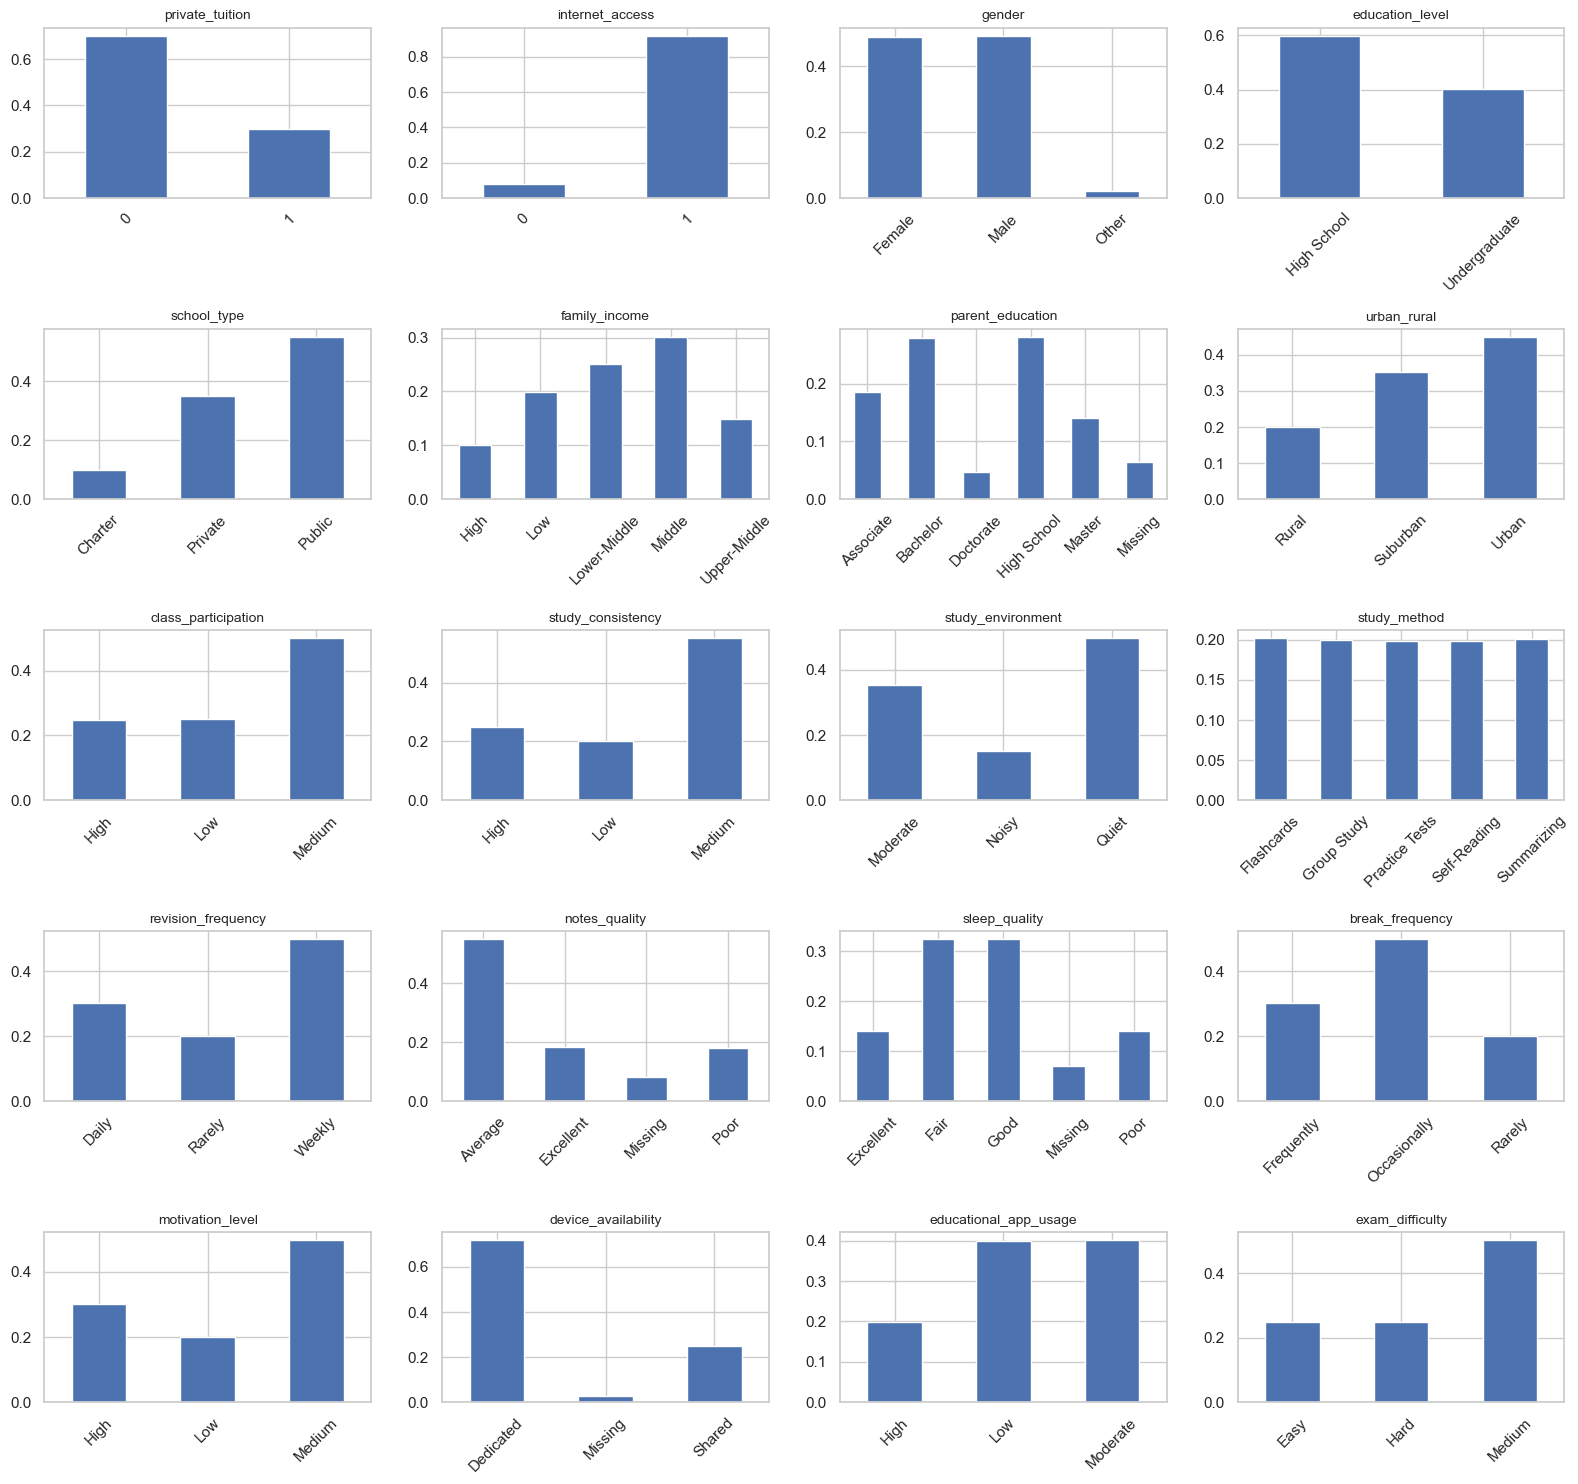

In [15]:
def bar_grid(cols, ncols=4):
    nrows = int(np.ceil(len(cols) / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(4 * ncols, 3 * nrows))
    axes = np.atleast_1d(axes).ravel()
    for ax, c in zip(axes, cols):
        vc = df[c].astype("object").fillna("Missing").value_counts(normalize=True)
        vc.sort_index().plot.bar(ax=ax)
        ax.set_title(c, fontsize=10)
        ax.set_xlabel("")
        ax.tick_params(axis="x", rotation=45)
    for ax in axes[len(cols):]:
        ax.axis("off")
    plt.tight_layout()
    plt.show()

bar_grid(binary_cols + cat_cols)

# Relationship between variables

Numeric and binary correlation (Pearson - linear rel., Spearman - monotonic rel.)

,pearson,spearman
previous_exam_score,0.494,0.479
previous_gpa,0.468,0.453
study_hours_per_day,0.363,0.341
self_study_hours,0.343,0.324
practice_tests_completed,0.316,0.299
assignment_completion_rate,0.221,0.210
exam_preparation_days,0.199,0.191
sleep_hours,0.171,0.163
attendance_percentage,0.169,0.161
stress_level,-0.162,-0.147


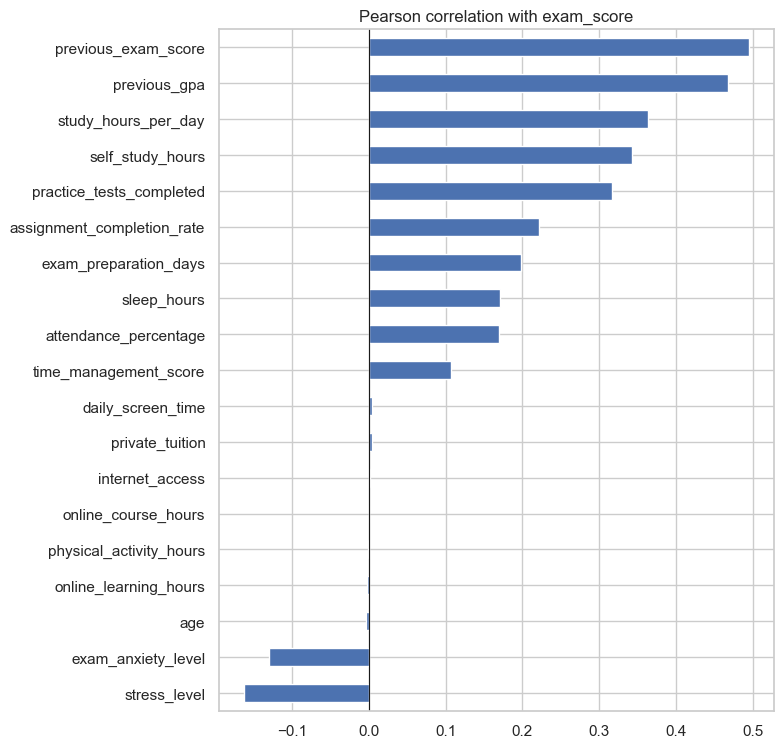

In [16]:
cols = num_cols + binary_cols
corr = pd.DataFrame({
    "pearson": df[cols].corrwith(df[TARGET]),
    "spearman": df[cols].corrwith(df[TARGET], method="spearman"),
}).sort_values("pearson", key=abs, ascending=False)

display(corr.round(3))

fig, ax = plt.subplots(figsize=(8, 0.35 * len(corr) + 1))
corr["pearson"].sort_values().plot.barh(ax=ax)
ax.axvline(0, color="k", lw=0.8)
ax.set_title("Pearson correlation with exam_score")
plt.tight_layout()
plt.show()

relationship between the most influential features and exam_score

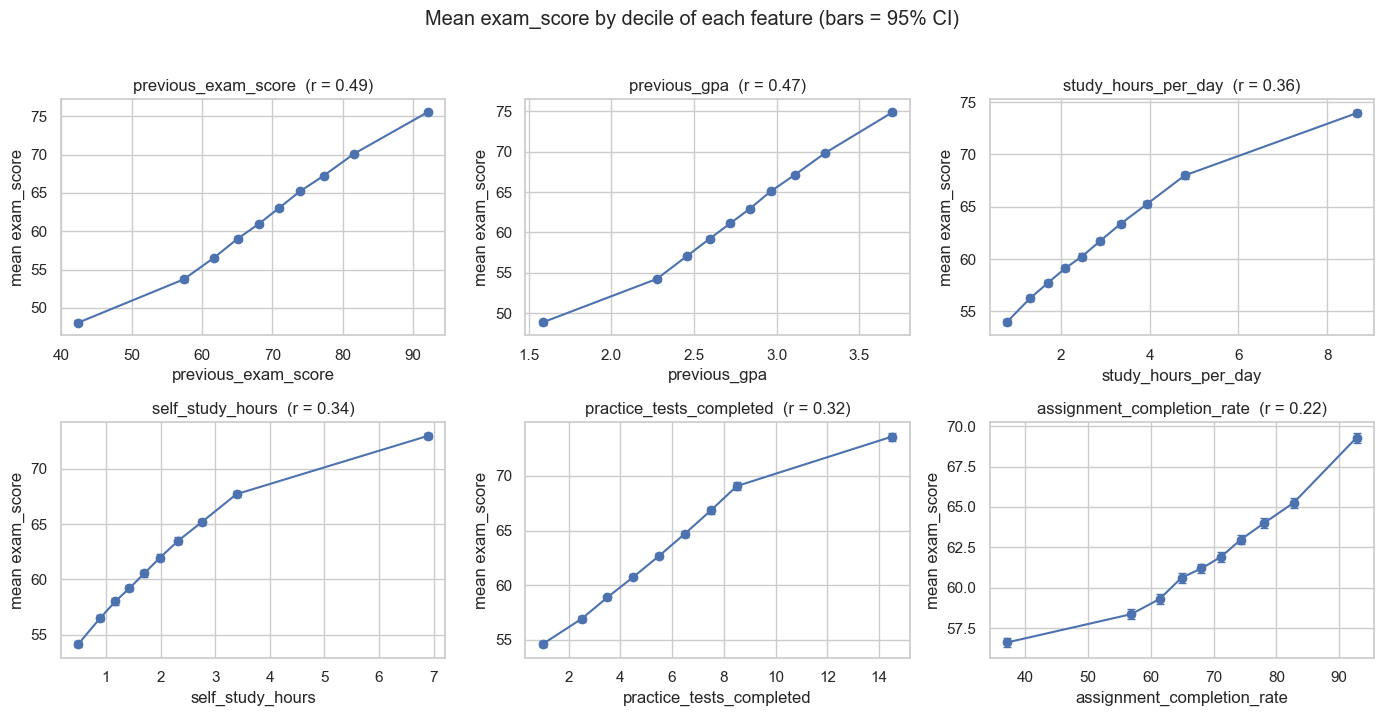

In [41]:
top = corr.index[:6]
fig, axes = plt.subplots(2, 3, figsize=(14, 7))
for ax, c in zip(axes.ravel(), top):
    if c in binary_cols:
        g = df.groupby(c)[TARGET].agg(["mean", "sem"])
        ax.errorbar(g.index, g["mean"], yerr=1.96 * g["sem"], fmt="o-", capsize=4)
        ax.set_xticks(g.index)
    else:
        bins = pd.qcut(df[c], 10, duplicates="drop")
        g = df.groupby(bins, observed=True)[TARGET].agg(["mean", "sem"])
        x = g.index.map(lambda i: i.mid).astype(float)
        ax.errorbar(x, g["mean"], yerr=1.96 * g["sem"], fmt="o-", capsize=3)
    ax.set_title(f"{c}  (r = {corr.loc[c, 'pearson']:.2f})")
    ax.set_xlabel(c)
    ax.set_ylabel("mean exam_score")
plt.suptitle("Mean exam_score by decile of each feature (bars = 95% CI)", y=1.02)
plt.tight_layout()
plt.show()

eta squared -  how much of the variation os explained by its cathegory, exam_difficulty - a lot, not the others tho.

,eta_squared
exam_difficulty,0.1114
family_income,0.0148
break_frequency,0.0001
parent_education,0.0001
school_type,0.0001
notes_quality,0.0001
study_method,0.0000
sleep_quality,0.0000
class_participation,0.0000
urban_rural,0.0000


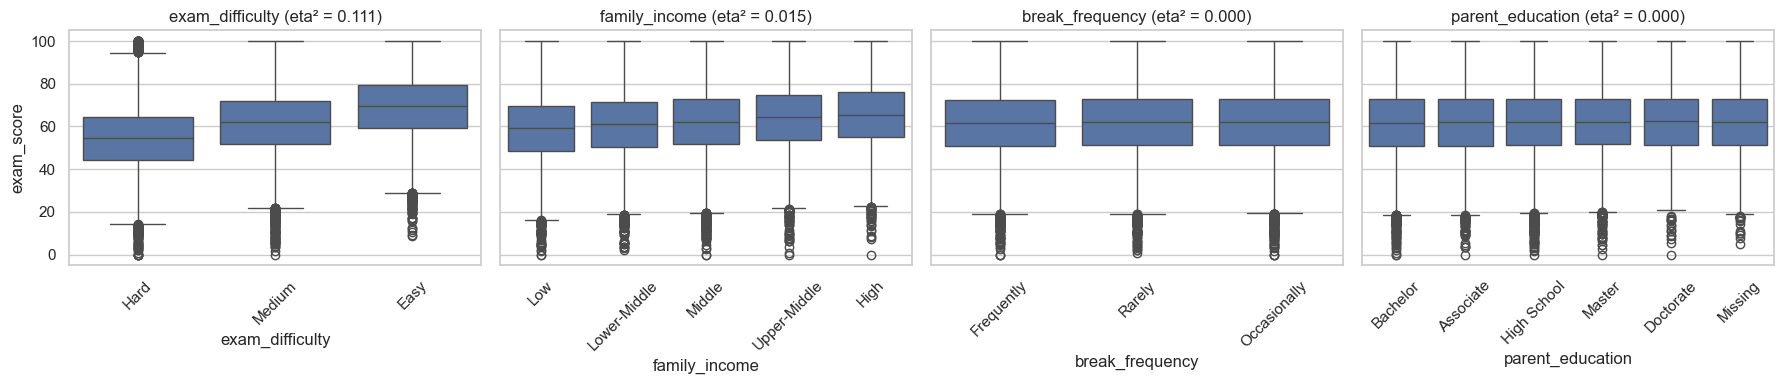

In [17]:
def eta_squared(groups, y):
    d = pd.DataFrame({"g": groups.astype("object").fillna("Missing"), "y": y})
    grand = d["y"].mean()
    ss_between = d.groupby("g")["y"].apply(lambda s: len(s) * (s.mean() - grand) ** 2).sum()
    return ss_between / ((d["y"] - grand) ** 2).sum()

eta = pd.Series({c: eta_squared(df[c], df[TARGET]) for c in cat_cols}).sort_values(ascending=False)
display(eta.round(4).to_frame("eta_squared"))

top_cat = eta.index[:4]
fig, axes = plt.subplots(1, len(top_cat), figsize=(4.5 * len(top_cat), 4), sharey=True)
axes = np.atleast_1d(axes)
for ax, c in zip(axes, top_cat):
    tmp = df[[c, TARGET]].copy()
    tmp[c] = tmp[c].astype("object").fillna("Missing")
    order = tmp.groupby(c)[TARGET].mean().sort_values().index
    sns.boxplot(data=tmp, x=c, y=TARGET, order=order, ax=ax)
    ax.set_title(f"{c} (eta² = {eta[c]:.3f})")
    ax.tick_params(axis="x", rotation=45)
plt.tight_layout()
plt.show()

In [36]:
# Imports 

from sklearn.model_selection import train_test_split, KFold, cross_val_score
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LinearRegression, LassoCV, Lasso
from sklearn.metrics import r2_score, mean_squared_error

assert not set(REDUNDANT_COLS) & set(features), "REDUNDANT_COLS still in features"
#keeping only rows with no missing value in the chosen columns (could improve this?)

data = df.dropna(subset=features)
print(f"{len(data)} of {len(df)} rows kept")


62897 of 100000 rows kept


In [37]:
# train/test split 80/20

X = data[features]
y = data[TARGET]
X_train, X_test, y_train, y_test = train_test_split(X,y, test_size=0.2, random_state=42)
print(X_train.shape, X_test.shape)

(50317, 32) (12580, 32)


In [49]:
# some preprocessing

def build_pre(cols):
    num = [c for c in num_cols + binary_cols if c in cols]
    cat = [c for c in cat_cols if c in cols]
    return ColumnTransformer([("num", StandardScaler(), num),
                              ("cat", OneHotEncoder(drop="first", handle_unknown="ignore", sparse_output=False),cat),
    ])

def make_pipe(model, cols=None):
    cols = features if cols is None else cols
    return Pipeline([("pre", build_pre(cols)), ("model", model)])

#prepared training data
pre = build_pre(features)
Z = pd.DataFrame(pre.fit_transform(X_train), columns=pre.get_feature_names_out(), index=X_train.index)
print(Z.shape)

(50317, 55)


,coef,ci_low,ci_high,p_value
cat__exam_difficulty_Hard,-15.091,-15.331,-14.852,0.000
num__previous_exam_score,7.721,7.635,7.807,0.000
cat__exam_difficulty_Medium,-7.528,-7.734,-7.321,0.000
num__self_study_hours,4.089,3.992,4.187,0.000
num__practice_tests_completed,3.577,3.488,3.666,0.000
num__exam_preparation_days,3.062,2.978,3.146,0.000
num__attendance_percentage,2.275,2.181,2.370,0.000
num__stress_level,-2.146,-2.232,-2.060,0.000
num__sleep_hours,2.033,1.946,2.120,0.000
num__time_management_score,1.295,1.210,1.380,0.000


R^2 on training data = 0.632


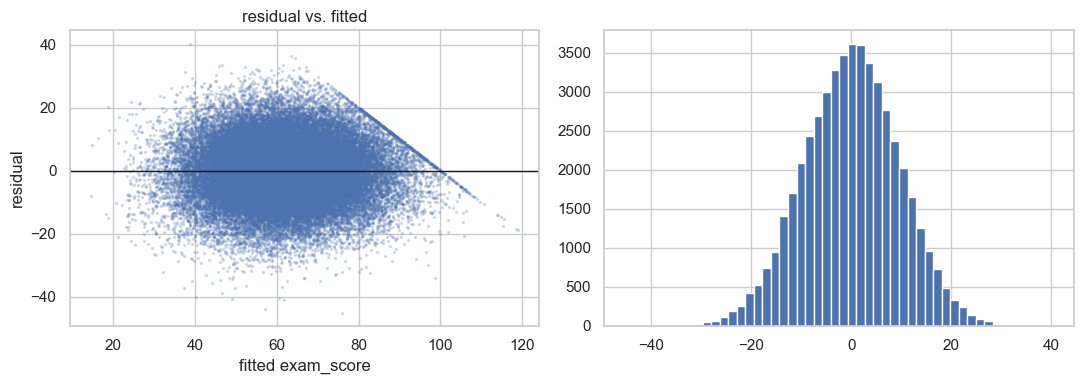

In [46]:
# linear regression

A = np.column_stack([np.ones(len(Z)), Z.values])
names = ["const"] + list(Z.columns)
beta, *_ = np.linalg.lstsq(A, y_train.values, rcond=None)
fitted = A @ beta
resid = y_train.values - fitted

dof = len(y_train) - A.shape[1] #degs of freedom
sigma2 = resid @ resid /dof
se = np.sqrt(np.diag(np.linalg.inv(A.T @ A)) * sigma2)
p = 2* stats.t.sf(np.abs(beta/se), dof)
tcrit = stats.t.ppf(0.975, dof)

ols_tab = pd.DataFrame({"coef": beta, "ci_low": beta-tcrit*se,
                        "ci_high": beta+tcrit*se, "p_value":p}, index=names).drop("const")
r2_train = 1- resid@resid/ ((y_train.values - y_train.mean())**2). sum()

display(ols_tab.reindex(ols_tab["coef"].abs().sort_values(ascending=False).index).round(3).head(25))
print(f"R^2 on training data = {r2_train:.3f}")

fig,ax = plt.subplots(1,2,figsize=(11,4))
ax[0].scatter(fitted, resid, s=2, alpha=0.2)
ax[0].axhline(0, color='k', lw=1)
ax[0].set(xlabel="fitted exam_score", ylabel="residual", title="residual vs. fitted")
ax[1].hist(resid, bins=50)
plt.tight_layout()
plt.show()



test R^2 = 0.636
test rmse = 9.62 points


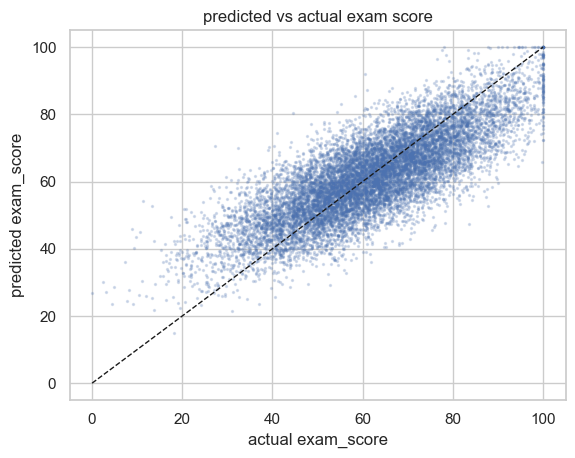

In [50]:
#prediction 

lin = make_pipe(LinearRegression())
lin.fit(X_train, y_train)

pred = lin.predict(X_test)
pred_clipped = np.clip(pred,0,100) #exam score is between 0 and 100
print(f"test R^2 = {r2_score(y_test, pred):.3f}")
print(f"test rmse = {mean_squared_error(y_test, pred)**0.5:.2f} points")

#predicted vs. actual 
plt.scatter(y_test, pred_clipped, s=2, alpha=0.2)
plt.plot([0,100],[0,100], "k--", lw=1)
plt.xlabel("actual exam_score")
plt.ylabel("predicted exam_score")
plt.title("predicted vs actual exam score")
plt.show()

alpha (lowest CV error)= 0.0239, alpha


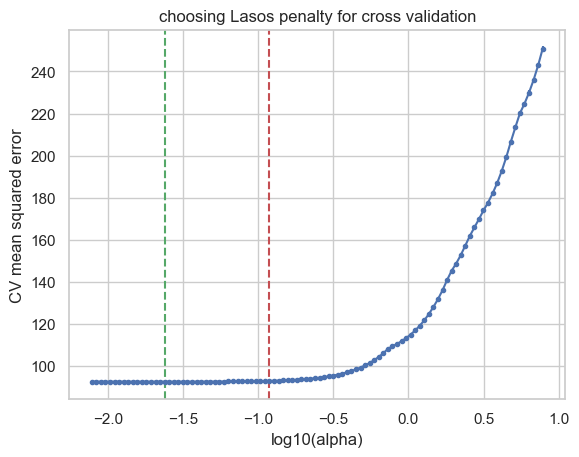

11 of 55 coefs are non-zero


cat__exam_difficulty_Hard         -13.646
num__previous_exam_score            7.613
cat__exam_difficulty_Medium        -6.322
num__self_study_hours               4.010
num__practice_tests_completed       3.491
num__exam_preparation_days          2.942
num__attendance_percentage          2.173
num__stress_level                  -2.047
num__sleep_hours                    1.950
num__time_management_score          1.187
num__assignment_completion_rate     0.300
dtype: float64

In [59]:
# lasso 

lasso_cv = LassoCV(cv=5, random_state=42, n_jobs=-1)
lasso_cv.fit(Z, y_train)

mse = lasso_cv.mse_path_.mean(axis=1)
se = lasso_cv.mse_path_.std(axis=1)/ np.sqrt(lasso_cv.mse_path_.shape[1])
i_min = mse.argmin()
alpha_min = lasso_cv.alphas_[i_min]
alpha_1se = lasso_cv.alphas_[mse <= mse[i_min] + se[i_min]].max()
print(f"alpha (lowest CV error)= {alpha_min:.4f}, alpha")

plt.errorbar(np.log10(lasso_cv.alphas_), mse, yerr=se, fmt="o-", ms=3)
plt.axvline(np.log10(alpha_min), ls="--", c="g", label="lowest CV error")
plt.axvline(np.log10(alpha_1se), ls="--", c="r", label="one-SE rule")
plt.xlabel("log10(alpha)")
plt.ylabel("CV mean squared error")
plt.title("choosing Lasos penalty for cross validation")
plt.show()

# gives the most imporant variables

lasso = Lasso(alpha=alpha_1se).fit(Z, y_train)
lasso_coef = pd.Series(lasso.coef_, index=Z.columns)
print(f"{(lasso_coef != 0).sum()} of {len(lasso_coef)} coefs are non-zero")
display(lasso_coef[lasso_coef != 0].sort_values(key=abs, ascending=False).round(3))

### Cross validation 

In [60]:
models = { "Linear Regression": make_pipe(LinearRegression()),
           "Lasso": make_pipe(LassoCV(cv=5, random_state=42)),}

cv = KFold(n_splits=5, shuffle=True, random_state=42)
rows=[]
for name, model in models.items():
    r2 = cross_val_score(model, X_train, y_train, cv=cv, scoring="r2")
    rmse = -cross_val_score(model, X_train, y_train, cv=cv, scoring="neg_root_mean_squared_error")
    rows.append({"model": name, "CV R^2 mean": r2.mean(), "CV R^2 sd": r2.std(), "CV RMSE mean": rmse.mean()})
display(pd.DataFrame(rows).set_index("model").round(3))

,CV R^2 mean,CV R^2 sd,CV RMSE mean
model,,,
Linear Regression,0.631,0.005,9.624
Lasso,0.631,0.005,9.620


In [61]:
def original_column(feature_name):
    if feature_name.startswith("num__"):
        return feature_name[len("num__"):]
    name = feature_name[len("cat__"):]
    return next(c for c in cat_cols if name.startswith(c + "_"))

kept = sorted({original_column(n) for n in lasso_coef[lasso_coef != 0].index})
dropped = [c for c in features if c not in kept]
print(f"Lasso keeps {len(kept)} of {len(features)} variables.")
print("Dropped:", dropped)

# fit linear regression on the kept variables only 
reduced = make_pipe(LinearRegression(), kept)
r2 = cross_val_score(reduced, X_train, y_train, cv=cv, scoring="r2")
reduced.fit(X_train, y_train)
pred = reduced.predict(X_test)
print(f"Reduced linear regression: CV R² = {r2.mean():.3f}, test R² = {r2_score(y_test, pred):.3f}, "
      f"test RMSE = {mean_squared_error(y_test, pred) ** 0.5:.2f}")

Lasso keeps 10 of 32 variables.
Dropped: ['age', 'gender', 'education_level', 'school_type', 'family_income', 'parent_education', 'urban_rural', 'class_participation', 'private_tuition', 'study_consistency', 'study_environment', 'study_method', 'revision_frequency', 'notes_quality', 'sleep_quality', 'daily_screen_time', 'physical_activity_hours', 'break_frequency', 'motivation_level', 'device_availability', 'educational_app_usage', 'online_course_hours']
Reduced linear regression: CV R² = 0.631, test R² = 0.637, test RMSE = 9.62
